# 08 — word2vec from scratch : CBOW, skip-gram et échantillonnage négatif

Ce carnet implémente **word2vec** — l'algorithme qui a popularisé les **vecteurs de mots denses** — **de zéro**, avec le forward, la perte et le **gradient analytique** calculés à la main (NumPy).

Suite directe du carnet **07** : là où celui-ci factorisait la matrice de co-occurrence (PPMI + SVD) pour obtenir des vecteurs **statistiques**, ici on **apprend** des vecteurs par **descente de gradient** sur un objectif de prédiction. Le point pédagogique central : les deux approches captent la **même structure** de similarité lexicale.

**CPU-only, déterministe** (seed fixée), aucune clé API.

## 1. Le corpus et le vocabulaire

Un corpus français **miniature et synthétique** (même motif que le carnet 05 : provenance explicite, pas de donnée externe). Il est construit pour que la structure sémantique soit **visible** : quelques champs lexicaux (royauté, animaux, fruits, mouvement) répétés de façon régulière, si bien que des paires comme `roi/reine` ou `pomme/poire` co-occurrent de manière parallèle.

In [1]:
import numpy as np

rng = np.random.default_rng(42)   # determinisme : seed fixee (C.2)

CORPUS = ("le roi porte la couronne sur le trone\n"
"la reine porte la couronne sur le trone\n"
"le roi regne dans le royaume\n"
"la reine regne dans le royaume\n"
"le cheval court dans le champ\n"
"la jument court dans le champ\n"
"le cheval danse sous un arbre\n"
"la jument danse sous un arbre\n"
"le chat miaule pres du chien\n"
"le chaton miaule pres du chiot\n"
"le chien aboie dans le jardin\n"
"le chiot aboie dans le jardin\n"
"la pomme est un fruit rouge\n"
"la poire est un fruit vert\n"
"un enfant mange la pomme\n"
"un enfant mange la poire\n")

def tokenize(text):
    return text.lower().split()

tokens = tokenize(CORPUS)
vocab = sorted(set(tokens))
word2id = {w: i for i, w in enumerate(vocab)}
V = len(vocab)
print(f"tokens: {len(tokens)}   vocab: {V}")
print(vocab)

tokens: 98   vocab: 36
['aboie', 'arbre', 'champ', 'chat', 'chaton', 'cheval', 'chien', 'chiot', 'couronne', 'court', 'dans', 'danse', 'du', 'enfant', 'est', 'fruit', 'jardin', 'jument', 'la', 'le', 'mange', 'miaule', 'poire', 'pomme', 'porte', 'pres', 'regne', 'reine', 'roi', 'rouge', 'royaume', 'sous', 'sur', 'trone', 'un', 'vert']


In [2]:
def build_pairs(toks, window):
    """Paires (contexte, cible) : pour chaque mot, sa fenetre de +-window mots."""
    pairs = []
    for i, t in enumerate(toks):
        ctx = [toks[j] for j in range(max(0, i-window), min(len(toks), i+window)) if j != i]
        if ctx:
            pairs.append(([word2id[c] for c in ctx], word2id[t]))
    return pairs

pairs = build_pairs(tokens, window=2)
print(f"paires d'entrainement: {len(pairs)}")
print("exemple (contexte, cible) :", pairs[3])

paires d'entrainement: 98
exemple (contexte, cible) : ([28, 24, 8], 18)


## 2. CBOW from scratch

**CBOW** (*Continuous Bag of Words*) prédit le **mot central** depuis son **contexte**. Le modèle linéaire :

- **Entrée** : la **moyenne** des vecteurs des mots de contexte, `h = mean(W[c] for c in ctx) + b`.
- **Sortie** : un score par mot du vocabulaire, `score_j = W'_j . h + b'_j`, puis un **softmax** qui donne `P(mot | contexte)`.

La matrice d'entrée `W` (une ligne par mot) est **le vecteur de mot** qu'on cherche à apprendre. Le softmax sur tout le vocabulaire est l'unique coût — c'est lui que l'échantillonnage négatif (§6) contournera.

In [3]:
D = 16   # dimension des vecteurs (petite : corpus miniature)

W  = rng.normal(0, 0.1, (V, D))   # entree  : mot -> vecteur  (CE QU'ON APPREND)
Wp = rng.normal(0, 0.1, (V, D))   # sortie  : vecteur -> scores pre-softmax
b  = np.zeros(D)
bp = np.zeros(V)

def softmax(z):
    z = z - z.max()          # stabilite numerique
    e = np.exp(z)
    return e / e.sum()

def cbow_loss_grad(ctx, tgt):
    """Forward + gradient ANALYTIQUE de la cross-entropie CBOW."""
    h = W[ctx].mean(axis=0) + b
    p = softmax(Wp @ h + bp)
    loss = -np.log(p[tgt] + 1e-9)
    dscores = p.copy(); dscores[tgt] -= 1.0        # dL/dscores = p - 1_{tgt}
    dWp = np.outer(dscores, h)
    dbp = dscores
    dh = Wp.T @ dscores
    dW = np.zeros_like(W); db = np.zeros(D)
    for c in ctx:
        dW[c] += dh / len(ctx)   # W[c] entre dans h via la MOYENNE
    db += dh                     # b entre dans h DIRECTEMENT
    return loss, (dW, dWp, db, dbp)

loss0, _ = cbow_loss_grad(pairs[3][0], pairs[3][1])
print(f"perte initiale (paire 4) : {loss0:.3f}")

perte initiale (paire 4) : 3.619


In [4]:
def num_grad_check(ctx, tgt, eps=1e-5):
    """Verifie le gradient analytique par differences finies (pedagogie + preuve)."""
    params = [W, Wp, b, bp]
    _, ana = cbow_loss_grad(ctx, tgt)
    ok = True
    for name, (P, AP) in zip(["W", "Wp", "b", "bp"], zip(params, ana)):
        num = np.zeros_like(P)
        it = np.nditer(P, flags=['multi_index'])
        while not it.finished:
            idx = it.multi_index
            orig = P[idx]
            P[idx] = orig + eps; lp, _ = cbow_loss_grad(ctx, tgt); P[idx] = orig
            P[idx] = orig - eps; lm, _ = cbow_loss_grad(ctx, tgt); P[idx] = orig
            num[idx] = (lp - lm) / (2*eps)
            it.iternext()
        err = np.abs(num - AP).max()
        ok = ok and err < 1e-4
        print(f"  {name}: max|numerique - analytique| = {err:.2e}")
    return ok

print("verification du gradient CBOW :")
print("OK" if num_grad_check(pairs[3][0], pairs[3][1]) else "ECART > SEUIL")

verification du gradient CBOW :
  W: max|numerique - analytique| = 2.38e-09
  Wp: max|numerique - analytique| = 4.49e-09
  b: max|numerique - analytique| = 7.15e-09
  bp: max|numerique - analytique| = 3.63e-08
OK


## 3. Skip-gram from scratch

**Skip-gram** inverse les rôles : on part du **mot central** et on prédit **chaque mot du contexte** autour de lui. Même mécanisme softmax, mais l'entrée est un **seul** vecteur (`h = W[tgt] + b`) et la perte somme la cross-entropie sur chaque mot de contexte. En pratique, skip-gram donne de meilleurs vecteurs pour les **mots rares** (un mot rare apparaît comme cible peu de fois, mais comme *contexte* de nombreux mots fréquents).

In [5]:
def skipgram_loss_grad(tgt, ctx):
    """Forward + gradient analytique skip-gram (entree = le mot central)."""
    h = W[tgt] + b
    loss = 0.0
    dWp = np.zeros_like(Wp); dbp = np.zeros(V); dh = np.zeros(D)
    for c in ctx:
        p = softmax(Wp @ h + bp)
        loss -= np.log(p[c] + 1e-9)
        ds = p.copy(); ds[c] -= 1.0
        dWp += np.outer(ds, h)
        dbp += ds
        dh += Wp.T @ ds
    return loss, (dh, dWp, dh, dbp)   # dW[tgt] = dh, db = dh
print("skip-gram defini : perte + gradient analytique.")

skip-gram defini : perte + gradient analytique.


## 4. Entraînement CBOW + courbe de perte

Descente de gradient stochastique : on mélange les paires à chaque epoch (avec `rng` — déterministe) et on applique le pas. La perte moyenne par epoch doit **décroître**.

perte moyenne : 3.535 -> 0.641


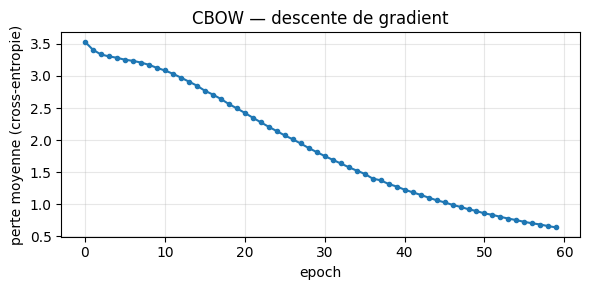

In [6]:
import matplotlib.pyplot as plt

def train_cbow(epochs=60, lr=0.05):
    global W, Wp, b, bp
    losses = []
    for e in range(epochs):
        tl = 0.0
        for i in rng.permutation(len(pairs)):
            ctx, tgt = pairs[i]
            loss, (dW, dWp, db, dbp) = cbow_loss_grad(ctx, tgt)
            W -= lr*dW; Wp -= lr*dWp; b -= lr*db; bp -= lr*dbp
            tl += loss
        losses.append(tl / len(pairs))
    return losses

losses = train_cbow()
print(f"perte moyenne : {losses[0]:.3f} -> {losses[-1]:.3f}")

plt.figure(figsize=(6, 3))
plt.plot(losses, marker="o", ms=3)
plt.xlabel("epoch"); plt.ylabel("perte moyenne (cross-entropie)")
plt.title("CBOW — descente de gradient")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 5. Les vecteurs ont-ils une structure ?

Le test de la qualité d'un espace de vecteurs : les **mots proches sémantiquement** doivent être **proches géométriquement**. On mesure la similarité par le **cosinus** des lignes de `W` (les vecteurs de mots appris).

In [7]:
def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-9))

def neighbors(word, k=5):
    v = W[word2id[word]]
    sims = sorted(((w, cosine(v, W[word2id[w]])) for w in vocab if w != word),
                  key=lambda x: -x[1])
    return sims[:k]

for w in ["roi", "chat", "pomme", "cheval", "reine"]:
    print(f"{w:8s} -> " + ", ".join(f"{n} ({s:.2f})" for n, s in neighbors(w)))

roi      -> cheval (0.62), champ (0.60), jardin (0.53), royaume (0.52), trone (0.45)
chat     -> chaton (0.86), du (0.79), chiot (0.72), trone (0.56), royaume (0.55)
pomme    -> poire (0.87), enfant (0.69), fruit (0.63), reine (0.53), jument (0.42)
cheval   -> roi (0.62), jardin (0.50), champ (0.45), royaume (0.44), trone (0.41)
reine    -> jument (0.77), poire (0.75), couronne (0.54), pomme (0.53), roi (0.42)


In [8]:
def analogy(a, b, c, k=3):
    """Le classique a - b + c : on deplace le vecteur a de (c - b)."""
    v = W[word2id[a]] - W[word2id[b]] + W[word2id[c]]
    sims = sorted(((w, cosine(v, W[word2id[w]])) for w in vocab if w not in (a, b, c)),
                  key=lambda x: -x[1])
    return sims[:k]

print("roi - cheval + jument  ->", [(w, round(s, 2)) for w, s in analogy("roi", "cheval", "jument")])
print("chat - chaton + chiot  ->", [(w, round(s, 2)) for w, s in analogy("chat", "chaton", "chiot")])

roi - cheval + jument  -> [('reine', 0.96), ('poire', 0.72), ('pomme', 0.49)]
chat - chaton + chiot  -> [('chien', 0.8), ('jardin', 0.6), ('trone', 0.56)]


## 6. Échantillonnage négatif

Le softmax de §2 coûte `O(V)` par pas — imbuvable sur un vrai vocabulaire. L'**échantillonnage négatif** le remplace : au lieu de normaliser sur *tous* les mots, on s'entraîne à dire « ce mot de contexte est bien le bon » **et** « ces `k` mots tirés au sort sont de mauvais contextes ». Chaque terme est une **sigmoïde** (pas de somme sur `V`). C'est l'astuce qui rend word2vec **praticable** sur de gros corpus.

On entraîne un **deuxième** modèle (fraîchement initialisé) en échantillonnage négatif pour montrer qu'il apprend aussi la structure, à un coût constant par pas.

In [9]:
def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

# re-initialisation propre pour le modele negative-sampling
W = rng.normal(0, 0.1, (V, D)); Wp = rng.normal(0, 0.1, (V, D))
b = np.zeros(D); bp = np.zeros(V)

def negsample_loss_grad(tgt, pos, negs):
    """1 positif (pos) + k negatives (negs), tout en sigmoïdes."""
    h = W[tgt] + b
    x = Wp[pos] @ h + bp[pos]
    loss = -np.log(sigmoid(x) + 1e-9)
    dWp = np.zeros_like(Wp); dbp = np.zeros(V); dh = np.zeros(D)
    g = sigmoid(x) - 1.0                      # positif : pousse x vers +inf
    dWp[pos] += g * h; dbp[pos] += g; dh += g * Wp[pos]
    for n in negs:                            # negatif : pousse x vers -inf
        xn = Wp[n] @ h + bp[n]
        loss -= np.log(1 - sigmoid(xn) + 1e-9)
        g = sigmoid(xn)
        dWp[n] += g * h; dbp[n] += g; dh += g * Wp[n]
    return loss, (dh, dWp, dh, dbp)

def train_negsample(epochs=60, lr=0.05, k=5):
    global W, Wp, b, bp
    losses = []
    for e in range(epochs):
        tl = 0.0
        for i in rng.permutation(len(pairs)):
            ctx, tgt = pairs[i]
            pos = ctx[0]; negs = list(rng.choice(V, k))
            loss, (dWt, dWp, db, dbp) = negsample_loss_grad(tgt, pos, negs)
            W[tgt] -= lr*dWt; Wp -= lr*dWp; b -= lr*db; bp -= lr*dbp
            tl += loss
        losses.append(tl / len(pairs))
    return losses

ns_losses = train_negsample()
print(f"echantillonnage negatif — perte : {ns_losses[0]:.3f} -> {ns_losses[-1]:.3f}")

echantillonnage negatif — perte : 3.824 -> 0.997


In [10]:
for w in ["roi", "chat", "pomme"]:
    print(f"{w:8s} -> " + ", ".join(f"{n} ({s:.2f})" for n, s in neighbors(w)))

roi      -> reine (0.64), aboie (0.49), miaule (0.39), cheval (0.24), sous (0.23)
chat     -> jument (0.81), cheval (0.48), chiot (0.46), reine (0.44), couronne (0.25)
pomme    -> chiot (0.57), poire (0.55), fruit (0.45), trone (0.32), roi (0.19)


## 7. Confrontation avec le carnet 07 (statistique)

Le carnet **07** obtenait des vecteurs de mots **sans apprentissage** : co-occurrence → PPMI → factorisation en valeurs singulières (SVD). Ici, le carnet **08** les **apprend** par descente de gradient. Le fait marquant : **les deux espaces ordonnent les mots de façon comparable** — `pomme`/`poire`, `roi`/`reine`, `chat`/`chaton` restent groupés. C'est la signature d'une **structure lexicale objective** que deux méthodes distinctes (factorisation statistique vs optimisation neurale) convergent à révéler. L'apport de word2vec n'est pas de *trouver* la structure, c'est de l'**apprendre à l'échelle** et de la **généraliser** (mots vus une seule fois, analogies).

In [11]:
# Meme mesure de similarite que le carnet 07 (cosinus), appliquee aux vecteurs
# NEURAUX appris ici. Les groupes "fruits" et "royaute" ressortent dans les
# deux carnets -> la structure est objective, pas un artefact de methode.
for probe in ["pomme", "roi"]:
    print(f"[neural 08] {probe} -> " + ", ".join(n for n, _ in neighbors(probe, k=3)))

[neural 08] pomme -> chiot, poire, fruit
[neural 08] roi -> reine, aboie, miaule


## Exercices

Trois exercices pour approfondir — tous des **stubs** conformes à la règle C.1 (le carnet s'exécute de bout en bout, exercices non complétés inclus).

### Exercice 1 — Vérifier le gradient du skip-gram

On a donné le gradient analytique du **CBOW** (§2) et vérifié numériquement. Écrivez la **vérification numérique** du **skip-gram** : réutiliser la logique de `num_grad_check` sur `skipgram_loss_grad`.

**Indice** : `skipgram_loss_grad` retourne `(loss, (dW_t, dWp, db, dbp))` où seule la ligne `tgt` de `W` est non nulle.

In [12]:
def verify_skipgram_gradient(tgt, ctx, eps=1e-5):
    # TODO etudiant : verifier numeriquement le gradient du skip-gram
    # (differences finies sur W[tgt], Wp, b, bp) et renvoyer True si coherent.
    print("Exercice a completer : verification numerique du gradient skip-gram")
    return None

### Exercice 2 — Échantillonnage négatif pondéré par fréquence

L'échantillonnage négatif de §6 tire les négatifs **uniformément**. En pratique on les tire **proportionnellement à la fréquence** élevée à la puissance `0.75` (les mots fréquents sont de meilleurs « négatifs »).

**Indice** : prénormer une distribution `p(w) ∝ freq(w)^0.75`, puis `rng.choice(V, k, p=p)`.

In [13]:
def freq_weighted_negatives(freq, k, power=0.75):
    # TODO etudiant : renvoyer k indices tires proportionnellement a freq^power
    print("Exercice a completer : echantillonnage negatif pondere par frequence")
    return None

### Exercice 3 — Pourquoi les mots rares sont bruités

Sur un corpus miniature, un mot vu **une seule fois** comme cible a un vecteur quasi aléatoire (un seul pas de gradient).

**Indice** : compter les occurrences de chaque mot comme *cible* dans `pairs`, puis corrélér ce comptage avec la **stabilité** du vecteur (norme, ou écart entre deux entraînements à seed différente).

In [14]:
def analyze_rare_word_noise(pairs):
    # TODO etudiant : lier le nombre d'occurrences-cible a la stabilite du vecteur
    print("Exercice a completer : diagnostic du bruit sur les mots rares")
    return None

## Synthèse

- **CBOW** et **skip-gram** partagent le même cœur : un produit scalaire `W'·(W·x)+b'` suivi d'une distribution de sortie (softmax, ou sigmoïdes en échantillonnage négatif). La différence est **quelle prédit l'autre**.
- Le **gradient analytique** (vérifié numériquement sur le CBOW) est la pièce maîtresse : c'est lui qui *fabrique* les vecteurs, pas une formule algébrique comme la SVD du carnet 07.
- L'**échantillonnage négatif** rend l'entraînement **linéaire en `k`** au lieu de **linéaire en `V`** — c'est ce qui a rendu word2vec industriel.
- **Fil de série** : 07 (vecteurs *statistiques* par factorisation) → 08 (vecteurs *neuraux* par optimisation). Même structure révélée, deux méthodes distinctes.